In [6]:
import numpy as np
from pathlib import Path
import tensorflow as tf

# ========================================
# 設定
# ========================================
IMAGE_SIZE = 9
N_CLASS = 3
DATA_DIR = Path("./TrainImage")

N_FILTER = 4
FILTER_SIZE = 3

LEARNING_RATE = 0.05
EPOCHS = 10

np.random.seed(0)
tf.random.set_seed(0)

In [7]:
# ========================================
# PNG画像の読み込み
# ========================================

X = []
T = []

for class_id in range(N_CLASS):
    class_dir = DATA_DIR / f"class_{class_id}"
    image_files = sorted(class_dir.glob("*.png"))

    for image_file in image_files:
        img = plt.imread(image_file)

        # RGBまたはRGBAの場合は最初のチャンネルを使用
        if img.ndim == 3:
            img = img[:, :, 0]

        # 画素値を0～1に正規化
        if img.max() > 1.0:
            img = img / 255.0

        # 画像サイズの確認
        if img.shape != (IMAGE_SIZE, IMAGE_SIZE):
            raise ValueError(
                f"画像サイズが不正です: {image_file} "
                f"実際のサイズ={img.shape}, "
                f"期待するサイズ={(IMAGE_SIZE, IMAGE_SIZE)}"
            )

        X.append(img)
        T.append(class_id)

X = np.array(X, dtype=np.float32)
T = np.array(T, dtype=int)

T_onehot = np.eye(N_CLASS, dtype=np.float32)[T]

# TensorFlowのConv2D用にチャンネル次元を追加
X = X[:, :, :, np.newaxis]

# クラスごとの画像枚数
class_counts = np.bincount(T, minlength=N_CLASS)

print("Loaded images:", len(X))
print("Image shape:", X.shape)
print("Class counts:", class_counts)

Loaded images: 300
Image shape: (300, 9, 9, 1)
Class counts: [100 100 100]


In [8]:
# ========================================
# ネットワークの設定
# ========================================

FEATURE_SIZE = IMAGE_SIZE - FILTER_SIZE + 1
N_FLAT = N_FILTER * FEATURE_SIZE * FEATURE_SIZE

print()
print("Input size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Filter size:", FILTER_SIZE, "x", FILTER_SIZE)
print("Feature size:", FEATURE_SIZE, "x", FEATURE_SIZE)
print("Number of filters:", N_FILTER)
print("Fully connected input:", N_FLAT)


Input size: 9 x 9
Filter size: 3 x 3
Feature size: 7 x 7
Number of filters: 4
Fully connected input: 196


In [9]:
# ========================================
# CNNモデルの定義
# ========================================

class CNN(tf.keras.Model):

    def __init__(self):
        super().__init__()

        # 畳み込み層
        self.conv = tf.keras.layers.Conv2D(
            filters=N_FILTER,
            kernel_size=(FILTER_SIZE, FILTER_SIZE),
            strides=1,
            padding="valid",
            activation="sigmoid",
            kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.1),
            bias_initializer="zeros"
        )

        # 全結合層
        self.fc = tf.keras.layers.Dense(
            N_CLASS,
            activation="softmax",
            kernel_initializer=tf.keras.initializers.RandomNormal(stddev=0.1),
            bias_initializer="zeros"
        )

    def call(self, x):

        # 畳み込み
        C = self.conv(x)

        # [高さ, 幅, フィルタ] → [フィルタ, 高さ, 幅]
        C = tf.transpose(C, [0, 3, 1, 2])

        # Flatten
        flat = tf.reshape(C, [-1, N_FLAT])

        # 全結合層
        y = self.fc(flat)

        return y


model = CNN()

In [10]:
# モデルの初期化
model(tf.zeros((1, IMAGE_SIZE, IMAGE_SIZE, 1)))

# ========================================
# 学習前の正解率
# ========================================

def predict(X):

    y = model(X, training=False)
    predictions = tf.argmax(y, axis=1).numpy()

    return predictions


pred_before = predict(X)
accuracy_before = np.mean(pred_before == T)

# ========================================
# TensorFlowのデータセット
# ========================================

dataset = tf.data.Dataset.from_tensor_slices((X, T_onehot))
dataset = dataset.shuffle(
    buffer_size=len(X),
    seed=0,
    reshuffle_each_iteration=True
)

In [11]:
# ========================================
# 学習処理
# ========================================
@tf.function
def train_step(x, t):
    with tf.GradientTape() as tape:

        # 1サンプルをバッチ次元付きに変換
        x = tf.expand_dims(x, axis=0)
        t = tf.expand_dims(t, axis=0)

        # 順伝播
        y = model(x, training=True)

        # 二乗誤差
        error = 0.5 * tf.reduce_sum(tf.square(y - t))

    # 自動微分による勾配計算
    gradients = tape.gradient(error, model.trainable_variables)

    # 重みの更新
    for variable, gradient in zip(model.trainable_variables, gradients):
        variable.assign_sub(LEARNING_RATE * gradient)

    return error, y

In [12]:
# ========================================
# 学習
# ========================================
error_history = []
accuracy_history = []

for epoch in range(EPOCHS):
    total_error = 0.0
    correct = 0
    for x, t in dataset:
        # 1サンプルずつ学習
        error, y = train_step(x, t)
        total_error += error.numpy()
        # 更新前の出力で正解率を計算
        if tf.argmax(y[0]).numpy() == tf.argmax(t).numpy():
            correct += 1
    # エポックごとの誤差と正解率
    error_history.append(total_error / len(X))
    accuracy_history.append(correct / len(X))
    if (epoch + 1) % 2 == 0:
        print(
            "Epoch:", epoch + 1,
            "Error:", error_history[-1],
            "Accuracy:", accuracy_history[-1]
        )

Epoch: 2 Error: 0.24621318869292735 Accuracy: 0.6266666666666667
Epoch: 4 Error: 0.06178466234831528 Accuracy: 0.9533333333333334
Epoch: 6 Error: 0.035352109742379983 Accuracy: 0.9766666666666667
Epoch: 8 Error: 0.027553385166408286 Accuracy: 0.9733333333333334
Epoch: 10 Error: 0.020656204120899323 Accuracy: 0.9766666666666667


In [13]:
# ========================================
# 学習後の評価
# ========================================

pred_after = predict(X)
accuracy_after = np.mean(pred_after == T)

print()
print("Accuracy before learning:", accuracy_before)
print("Accuracy after learning:", accuracy_after)


Accuracy before learning: 0.3333333333333333
Accuracy after learning: 0.9733333333333334


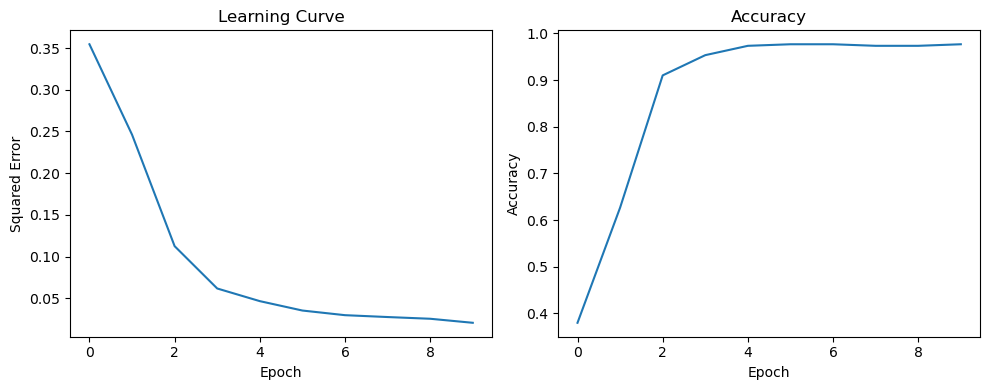

In [14]:
# ========================================
# 学習曲線
# ========================================
%matplotlib inline
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(error_history)
plt.xlabel("Epoch")
plt.ylabel("Squared Error")
plt.title("Learning Curve")

plt.subplot(1, 2, 2)
plt.plot(accuracy_history)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")

plt.tight_layout()
plt.show()

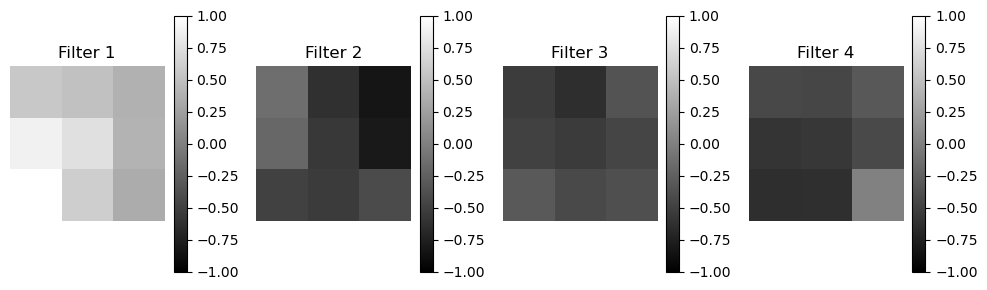

In [15]:
# ========================================
# 畳み込みフィルタの表示
# ========================================
# TensorFlowから畳み込みフィルタを取得
K = model.conv.kernel.numpy()

plt.figure(figsize=(10, 3))

for f in range(N_FILTER):
    plt.subplot(1, N_FILTER, f + 1)
    plt.imshow(K[:, :, 0, f], cmap="gray", vmin=-1, vmax=1)
    plt.colorbar()
    plt.title("Filter " + str(f + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

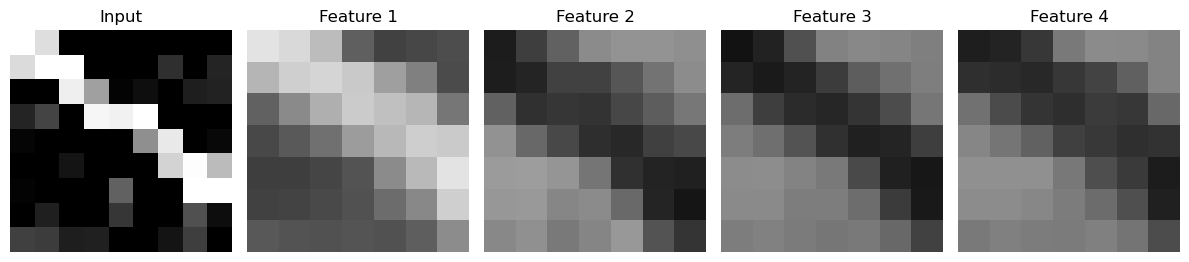

In [16]:
# ========================================
# 入力画像と特徴マップの表示
# ========================================

sample = 100

# 入力画像をTensorFlowに渡す
x = X[sample:sample+1]

# 畳み込み層の出力を取得
C = model.conv(x)

# [1, 高さ, 幅, フィルタ] → [フィルタ, 高さ, 幅]
C = tf.transpose(C, [0, 3, 1, 2]).numpy()[0]

plt.figure(figsize=(12, 3))

plt.subplot(1, N_FILTER + 1, 1)
plt.imshow(X[sample, :, :, 0], cmap="gray")
plt.title("Input")
plt.axis("off")

for f in range(N_FILTER):
    plt.subplot(1, N_FILTER + 1, f + 2)
    plt.imshow(C[f], cmap="gray", vmin=0, vmax=1)
    plt.title("Feature " + str(f + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

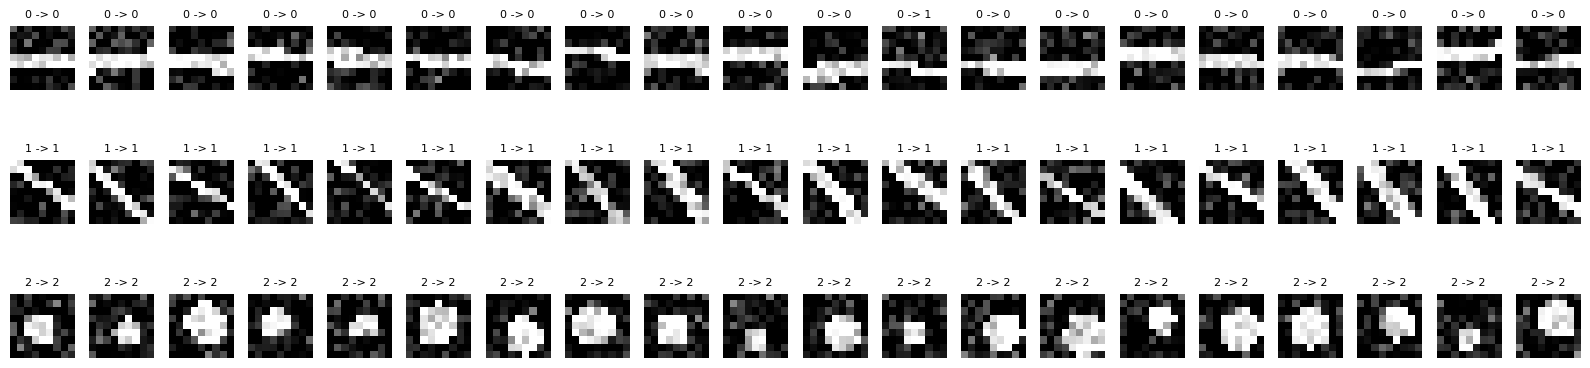

In [17]:
# ========================================
# 入力データと分類結果の表示
# ========================================

MAX_DISPLAY = 20

fig, axes = plt.subplots(
    N_CLASS,
    MAX_DISPLAY,
    figsize=(MAX_DISPLAY * 0.8, N_CLASS * 1.5),
    squeeze=False
)

for class_id in range(N_CLASS):

    indices = np.where(T == class_id)[0]

    for col in range(MAX_DISPLAY):

        ax = axes[class_id, col]

        if col < len(indices):

            n = indices[col]

            ax.imshow(X[n, :, :, 0], cmap="gray")
            ax.set_title(
                str(T[n]) + " -> " + str(pred_after[n]),
                fontsize=8
            )

        ax.axis("off")

plt.tight_layout()
plt.show()